# Mixture-of-Experts with Expert Sharding — JAX on TPU

This notebook builds a **sparse Mixture-of-Experts (MoE) layer** from scratch in JAX and shards its experts across TPU cores (*expert parallelism*).

What's inside:

1. **Device mesh** with a `data` axis and an `expert` axis.
2. **Top-k router** with expert capacity, token dropping, a load-balancing auxiliary loss and router z-loss (Switch / GShard style).
3. **Two expert-parallel implementations**:
   - **A. GSPMD**: write the math with `einsum`s, add `with_sharding_constraint`, and let XLA insert the `all-to-all`s.
   - **B. `shard_map`**: write the per-device program yourself with explicit `jax.lax.all_to_all`.
4. **Correctness checks**: both implementations against a dense reference, forward pass and gradients.
5. **HLO inspection**: confirm the compiled program really contains `all-to-all` collectives.
6. **Training** a small MoE network on a synthetic task where experts can specialize, plus expert-load and specialization plots.
7. **Benchmark** of A vs B.

**Runtime:** `Runtime → Change runtime type → TPU`. A multi-core runtime such as **v2-8** has 8 devices. Single-chip runtimes (v5e-1, v6e-1) have 1 device, so the code runs but there's nothing to shard across. To see real 8-way sharding anyway, set `FORCE_CPU_SIMULATION = True` in the next cell, which gives you 8 virtual CPU devices.

In [1]:
# ---- Must run BEFORE jax is imported ----
import os
FORCE_CPU_SIMULATION = False   # True -> 8 virtual CPU devices (shows sharding on any runtime)

if FORCE_CPU_SIMULATION:
    os.environ["JAX_PLATFORMS"] = "cpu"
    os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=8"

In [2]:
# Colab TPU runtimes ship with JAX preinstalled; we only need optax.
try:
    import optax  # noqa: F401
except ImportError:
    %pip install -q optax

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [3]:
import dataclasses, functools, math, time
from typing import Any

import numpy as np
import jax
import jax.numpy as jnp
from jax import lax
from jax.sharding import Mesh, NamedSharding, PartitionSpec as P
import optax
import matplotlib.pyplot as plt

# shard_map moved from jax.experimental to the top-level namespace in newer JAX.
try:
    from jax import shard_map
except ImportError:
    from jax.experimental.shard_map import shard_map

print("JAX version :", jax.__version__)
print("Backend     :", jax.default_backend())
print("Devices     :", jax.device_count())
for d in jax.devices():
    print("   ", d)
ON_TPU = jax.default_backend() == "tpu"

JAX version : 0.11.2
Backend     : tpu
Devices     : 1
    TPU_0(process=0,(0,0,0,0))


## 1. Device mesh

We use a 2-D mesh `('data', 'expert')`:

| tensor | sharding |
|---|---|
| tokens / activations | batch split over **both** axes `('data','expert')`, so every device holds a different slice of tokens |
| expert weights `w_in [E, M, H]`, `w_out [E, H, M]` | split along `E` over the **`expert`** axis, replicated over `data` |
| router, embeddings, head | replicated |

The expert-parallel degree is `gcd(n_devices, num_experts)`. With 8 devices and 8 experts each device owns exactly **one expert**.

In [4]:
NUM_EXPERTS = 8

n_dev = jax.device_count()
EP = math.gcd(n_dev, NUM_EXPERTS)   # expert-parallel degree
DP = n_dev // EP                      # data-parallel degree

try:
    from jax.experimental import mesh_utils
    dev_grid = mesh_utils.create_device_mesh((DP, EP))   # topology-aware on TPU
except Exception:
    dev_grid = np.array(jax.devices()).reshape(DP, EP)

mesh = Mesh(dev_grid, axis_names=("data", "expert"))
print(mesh)
print(f"data-parallel = {DP}, expert-parallel = {EP}, experts per device = {NUM_EXPERTS // EP}")
if n_dev == 1:
    print("\nOnly 1 device: everything runs, but no actual sharding happens. "
          "Use a v2-8 TPU or set FORCE_CPU_SIMULATION=True.")

TOKEN_AXES = ("data", "expert")       # batch is split over every device

Mesh('data': 1, 'expert': 1, axis_types=(Auto, Auto))
data-parallel = 1, expert-parallel = 1, experts per device = 8

Only 1 device: everything runs, but no actual sharding happens. Use a v2-8 TPU or set FORCE_CPU_SIMULATION=True.


## 2. Configuration and parameters

Tokens are processed in **groups** (here, one sequence = one group). Each expert gets a fixed-size buffer per group:

$$C = \left\lceil \frac{k \cdot S \cdot \text{capacity\_factor}}{E} \right\rceil$$

Fixed shapes keep XLA/TPU happy. Tokens that overflow an expert's buffer are **dropped**: they skip the MoE and pass through on the residual path.

In [5]:
@dataclasses.dataclass(frozen=True)
class MoEConfig:
    d_model: int = 512
    d_ff: int = 2048
    num_experts: int = NUM_EXPERTS
    top_k: int = 2
    capacity_factor: float = 1.25
    aux_loss_coef: float = 1e-2      # load-balancing loss weight
    z_loss_coef: float = 1e-3        # router z-loss weight
    compute_dtype: Any = jnp.bfloat16


def expert_capacity(cfg: MoEConfig, group_size: int) -> int:
    c = math.ceil(cfg.top_k * group_size * cfg.capacity_factor / cfg.num_experts)
    return max(int(c), 1)


def init_moe_params(key, cfg: MoEConfig):
    k_r, k_i, k_o = jax.random.split(key, 3)
    E, M, H = cfg.num_experts, cfg.d_model, cfg.d_ff
    return {
        "router": jax.random.normal(k_r, (M, E), jnp.float32) * 0.02,
        "w_in":   jax.random.normal(k_i, (E, M, H), jnp.float32) * M ** -0.5,
        "w_out":  jax.random.normal(k_o, (E, H, M), jnp.float32) * H ** -0.5,
    }


# PartitionSpecs for the MoE parameters: experts split over the 'expert' mesh axis.
MOE_PARAM_SPECS = {
    "router": P(),                       # replicated
    "w_in":   P("expert", None, None),   # [E, M, H] -> E split
    "w_out":  P("expert", None, None),   # [E, H, M] -> E split
}

## 3. Router: top-k gating with capacity

For every token the router produces:

* `dispatch[g, s, e, c]` (0/1): token `s` of group `g` goes to slot `c` of expert `e`
* `combine[g, s, e, c]`: the same, weighted by the gate probability, used to merge expert outputs back

Buffer slots are assigned in priority order: everyone's **1st choice before anyone's 2nd choice**. Under pressure, second choices get dropped first.

Auxiliary losses:
* **Load balancing** (Switch Transformer): `E · Σ_e f_e · P_e`, where `f_e` is the fraction of assignments to expert `e` and `P_e` is its mean router probability. It reaches its minimum of 1 when load is uniform.
* **Router z-loss** (ST-MoE): `mean(logsumexp(logits)²)`, which keeps router logits small and numerically stable.

The router always runs in **float32**.

In [6]:
def route(x, router_w, cfg: MoEConfig, capacity: int):
    # x: [G, S, M] -> dispatch, combine: [G, S, E, C], plus aux losses / stats.
    G, S, _ = x.shape
    E, K = cfg.num_experts, cfg.top_k

    logits = jnp.einsum("gsm,me->gse", x.astype(jnp.float32), router_w)
    probs = jax.nn.softmax(logits, axis=-1)

    gate, idx = lax.top_k(probs, K)                         # [G, S, K]
    gate = gate / jnp.sum(gate, axis=-1, keepdims=True)     # renormalise over the k picks
    expert_mask = jax.nn.one_hot(idx, E, dtype=jnp.int32)   # [G, S, K, E]

    # Position of each (token, choice) in its expert's buffer, k-major priority.
    m = expert_mask.transpose(0, 2, 1, 3).reshape(G, K * S, E)
    pos = jnp.cumsum(m, axis=1) - 1
    pos = pos.reshape(G, K, S, E).transpose(0, 2, 1, 3)     # [G, S, K, E]
    pos = jnp.sum(pos * expert_mask, axis=-1)               # [G, S, K]
    keep = (pos < capacity).astype(jnp.float32)             # dropped if buffer full

    pos_oh = jax.nn.one_hot(pos, capacity, dtype=jnp.float32) * keep[..., None]  # [G,S,K,C]
    emask = expert_mask.astype(jnp.float32)
    dispatch = jnp.einsum("gske,gskc->gsec", emask, pos_oh)
    combine = jnp.einsum("gske,gskc,gsk->gsec", emask, pos_oh, gate)

    # Auxiliary losses (averaged over groups).
    frac_assigned = jnp.mean(jnp.sum(emask, axis=2), axis=1) / K   # [G, E]
    mean_prob = jnp.mean(probs, axis=1)                           # [G, E]
    aux = {
        "lb_loss": jnp.mean(jnp.sum(frac_assigned * mean_prob, axis=-1)) * E,
        "z_loss": jnp.mean(jax.nn.logsumexp(logits, axis=-1) ** 2),
        "drop_frac": 1.0 - jnp.mean(keep),
        "expert_load": jnp.mean(frac_assigned, axis=0),           # [E]
    }
    return dispatch, combine, aux

## 4A. Expert parallelism via GSPMD (sharding annotations)

We write the computation as plain `einsum`s and mark the shardings we want:

```
x        [G, S, M]     G split over (data, expert)
dispatch → [E, G, C, M] E split over expert, G over data   ← all-to-all #1
expert FFN (local matmuls, each device uses only its own experts)
combine  → [G, S, M]   G split over (data, expert)          ← all-to-all #2
```

XLA's SPMD partitioner sees the resharding between the two layouts and lowers it to `all-to-all` collectives over the `expert` axis.

In [7]:
def _wsc(x, spec):
    return lax.with_sharding_constraint(x, NamedSharding(mesh, spec))


def moe_gspmd(params, x, cfg: MoEConfig):
    G, S, M = x.shape
    C = expert_capacity(cfg, S)
    cd = cfg.compute_dtype

    dispatch, combine, aux = route(x, params["router"], cfg, C)

    # Tokens -> expert buffers.  Reshard: G-sharded  ->  E-sharded  (all-to-all)
    x_e = jnp.einsum("gsec,gsm->egcm", dispatch.astype(cd), x.astype(cd))
    x_e = _wsc(x_e, P("expert", "data", None, None))

    # Expert FFN: purely local, each device multiplies its own experts' weights.
    h = jnp.einsum("egcm,emh->egch", x_e, params["w_in"].astype(cd))
    h = jax.nn.gelu(h)
    y_e = jnp.einsum("egch,ehm->egcm", h, params["w_out"].astype(cd))
    y_e = _wsc(y_e, P("expert", "data", None, None))

    # Expert buffers -> tokens.  Reshard: E-sharded -> G-sharded  (all-to-all)
    y = jnp.einsum("gsec,egcm->gsm", combine.astype(cd), y_e)
    y = _wsc(y, P(TOKEN_AXES, None, None))
    return y.astype(x.dtype), aux

## 4B. Expert parallelism via `shard_map` (explicit collectives)

Here we write the **per-device** program. Each device holds:
* `x_local [G/n_dev, S, M]`, its own tokens
* `w_in_local [E/EP, M, H]`, its own experts

```
route locally                         → x_e  [E,      G_l,      C, M]
all_to_all(split E, concat G)         → x_e  [E/EP,   G_l·EP,   C, M]   (send each expert's tokens to its owner)
local expert FFN
all_to_all(split G, concat E)         → y_e  [E,      G_l,      C, M]   (send results back)
combine locally
```

This gives exact control over communication, which helps when you want to overlap it with compute or use custom collectives later.

In [8]:
def moe_shard_map(params, x, cfg: MoEConfig):
    G, S, M = x.shape
    C = expert_capacity(cfg, S)
    cd = cfg.compute_dtype

    def per_device(router_w, w_in, w_out, x_l):
        dispatch, combine, aux = route(x_l, router_w, cfg, C)
        x_e = jnp.einsum("gsec,gsm->egcm", dispatch.astype(cd), x_l.astype(cd))   # [E, G_l, C, M]
        x_e = lax.all_to_all(x_e, "expert", split_axis=0, concat_axis=1, tiled=True)  # [E/EP, G_l*EP, C, M]

        h = jax.nn.gelu(jnp.einsum("egcm,emh->egch", x_e, w_in.astype(cd)))
        y_e = jnp.einsum("egch,ehm->egcm", h, w_out.astype(cd))

        y_e = lax.all_to_all(y_e, "expert", split_axis=1, concat_axis=0, tiled=True)  # [E, G_l, C, M]
        y = jnp.einsum("gsec,egcm->gsm", combine.astype(cd), y_e)

        aux = jax.tree.map(lambda a: lax.pmean(a, TOKEN_AXES), aux)   # global averages
        return y.astype(x_l.dtype), aux

    fn = shard_map(
        per_device,
        mesh=mesh,
        in_specs=(MOE_PARAM_SPECS["router"], MOE_PARAM_SPECS["w_in"],
                  MOE_PARAM_SPECS["w_out"], P(TOKEN_AXES, None, None)),
        out_specs=(P(TOKEN_AXES, None, None), P()),
    )
    return fn(params["router"], params["w_in"], params["w_out"], x)

## 5. Correctness checks

1. **Dense reference**: run every expert on every token and pick the top-k outputs, with no capacity limit. With a large enough capacity factor (no drops) both sharded versions must match it.
2. **A vs B**: with the normal capacity factor (tokens get dropped), the GSPMD and `shard_map` versions must agree on outputs, aux losses **and gradients**.

We use float32 with `matmul_precision="highest"` so the comparison is tight. On TPU the default float32 matmul runs as one bfloat16 pass, which gives errors around 1e-2 even when the code is correct.

In [9]:
def moe_dense_reference(params, x, cfg: MoEConfig):
    logits = jnp.einsum("gsm,me->gse", x, params["router"])
    gate, idx = lax.top_k(jax.nn.softmax(logits, -1), cfg.top_k)
    gate = gate / gate.sum(-1, keepdims=True)
    h = jax.nn.gelu(jnp.einsum("gsm,emh->gseh", x, params["w_in"]))
    y_all = jnp.einsum("gseh,ehm->gsem", h, params["w_out"])           # every expert, every token
    y_sel = jnp.take_along_axis(y_all, idx[..., None], axis=2)         # [G, S, K, M]
    return jnp.sum(y_sel * gate[..., None], axis=2)


def shard_moe_params(p):
    return {k: jax.device_put(v, NamedSharding(mesh, MOE_PARAM_SPECS[k])) for k, v in p.items()}


# On TPU, float32 matmuls default to a single bfloat16 pass (~1e-2 error). Use full
# float32 precision for the correctness checks so the tolerances are meaningful.
jax.config.update("jax_default_matmul_precision", "highest")

test_cfg = MoEConfig(d_model=64, d_ff=128, compute_dtype=jnp.float32)
G_test, S_test = 2 * n_dev, 32
key = jax.random.PRNGKey(0)
p_test = shard_moe_params(init_moe_params(key, test_cfg))
x_test = jax.device_put(jax.random.normal(jax.random.PRNGKey(1), (G_test, S_test, 64)),
                        NamedSharding(mesh, P(TOKEN_AXES, None, None)))

# (1) No-drop config vs dense reference
nodrop_cfg = dataclasses.replace(test_cfg, capacity_factor=test_cfg.num_experts / test_cfg.top_k)
ref = jax.jit(functools.partial(moe_dense_reference, cfg=nodrop_cfg))(p_test, x_test)
yA, auxA = jax.jit(functools.partial(moe_gspmd, cfg=nodrop_cfg))(p_test, x_test)
yB, auxB = jax.jit(functools.partial(moe_shard_map, cfg=nodrop_cfg))(p_test, x_test)
print("no-drop  | max|A-ref| =", float(jnp.max(jnp.abs(yA - ref))),
      "| max|B-ref| =", float(jnp.max(jnp.abs(yB - ref))), "| drop frac =", float(auxA["drop_frac"]))
np.testing.assert_allclose(yA, ref, atol=1e-4, rtol=1e-4)
np.testing.assert_allclose(yB, ref, atol=1e-4, rtol=1e-4)

# (2) Normal capacity: A vs B, forward and gradients
def loss_fn(moe_fn, params, x):
    y, aux = moe_fn(params, x, test_cfg)
    return jnp.mean(y ** 2) + 0.01 * aux["lb_loss"] + 1e-3 * aux["z_loss"], aux

(lA, auxA), gA = jax.jit(jax.value_and_grad(functools.partial(loss_fn, moe_gspmd), has_aux=True))(p_test, x_test)
(lB, auxB), gB = jax.jit(jax.value_and_grad(functools.partial(loss_fn, moe_shard_map), has_aux=True))(p_test, x_test)
print(f"capacity | loss A = {float(lA):.6f}  loss B = {float(lB):.6f} | drop frac = {float(auxA['drop_frac']):.3f}")
np.testing.assert_allclose(lA, lB, rtol=1e-5)
for k in gA:
    np.testing.assert_allclose(gA[k], gB[k], atol=1e-5, rtol=1e-4)
    print(f"  grad[{k:6s}] max|A-B| = {float(jnp.max(jnp.abs(gA[k] - gB[k]))):.2e}   sharding: {gA[k].sharding.spec}")
print("\n✅ All correctness checks passed.")
jax.config.update("jax_default_matmul_precision", None)   # back to fast TPU default

no-drop  | max|A-ref| = 1.1920928955078125e-07 | max|B-ref| = 1.1920928955078125e-07 | drop frac = 0.0
capacity | loss A = 0.214370  loss B = 0.214370 | drop frac = 0.031
  grad[router] max|A-B| = 0.00e+00   sharding: P()
  grad[w_in  ] max|A-B| = 0.00e+00   sharding: P()
  grad[w_out ] max|A-B| = 0.00e+00   sharding: P()

✅ All correctness checks passed.


## 6. Look at the sharding and the compiled HLO

`visualize_array_sharding` shows which device holds which slice of the expert weights. Counting collectives in the compiled HLO confirms the expected communication pattern: **2 all-to-alls forward**, plus the matching ones in the backward pass.

In [10]:
print("w_in [E, M, H] sharding (viewing the [E, M] slice; rows = experts):")
try:
    jax.debug.visualize_array_sharding(p_test["w_in"][:, :, 0])
except Exception as e:
    print("  (visualisation unavailable:", e, ")")
for s in p_test["w_in"].addressable_shards[:4]:
    print(f"  {s.device}  holds experts [{s.index[0].start}:{s.index[0].stop}]  shape {s.data.shape}")


def count_collectives(fn, *args):
    hlo = jax.jit(fn).lower(*args).compile().as_text()
    ops = ["all-to-all", "all-gather", "all-reduce", "reduce-scatter", "collective-permute"]
    return {op: hlo.count(f" {op}(") + hlo.count(f" {op}-start(") for op in ops}

print("\nCollectives in compiled FORWARD:")
print("  GSPMD     :", count_collectives(lambda p, x: moe_gspmd(p, x, test_cfg)[0], p_test, x_test))
print("  shard_map :", count_collectives(lambda p, x: moe_shard_map(p, x, test_cfg)[0], p_test, x_test))
print("Collectives in compiled FORWARD+BACKWARD:")
print("  GSPMD     :", count_collectives(lambda p, x: jax.grad(lambda p: loss_fn(moe_gspmd, p, x)[0])(p), p_test, x_test))
print("  shard_map :", count_collectives(lambda p, x: jax.grad(lambda p: loss_fn(moe_shard_map, p, x)[0])(p), p_test, x_test))

w_in [E, M, H] sharding (viewing the [E, M] slice; rows = experts):


                                                                                
                                                                                
                                                                                
                                                                                
                                                                                
                                     TPU 0                                      
                                                                                
                                                                                
                                                                                
                                                                                
                                                                                

  TPU_0(process=0,(0,0,0,0))  holds experts [None:None]  shape (8, 64, 128)

Collectives in compiled FORWARD:
  GSPMD     : {'all-to-all': 0, 'all-gather': 0, 'all-reduce': 0, 'reduce-scatter': 0, 'collective-permute': 0}
  shard_map : {'all-to-all': 0, 'all-gather': 0, 'all-reduce': 0, 'reduce-scatter': 0, 'collective-permute': 0}
Collectives in compiled FORWARD+BACKWARD:
  GSPMD     : {'all-to-all': 0, 'all-gather': 0, 'all-reduce': 0, 'reduce-scatter': 0, 'collective-permute': 0}
  shard_map : {'all-to-all': 0, 'all-gather': 0, 'all-reduce': 0, 'reduce-scatter': 0, 'collective-permute': 0}


## 7. Train a small MoE network

**Synthetic task:** inputs come from 8 Gaussian clusters, and each cluster has its *own* nonlinear target function `y = tanh(x·A_c)`. A model that routes each cluster to a dedicated expert has an easy job, so we should see:

* the loss going down,
* the load-balancing loss staying close to its minimum of 1.0,
* **experts specializing** in clusters (shown in the heatmap at the end).

**Model:** `Linear embed → L × [x + MoE(RMSNorm(x))] → RMSNorm → Linear head`, with every MoE layer expert-sharded. Matmuls run in bfloat16 on TPU.

In [11]:
# ---- model / data sizes (bigger on TPU) ----
if ON_TPU:
    D_IN, D_OUT, N_LAYERS = 64, 64, 2
    model_cfg = MoEConfig(d_model=512, d_ff=2048, compute_dtype=jnp.bfloat16)
    GROUPS_PER_DEVICE, GROUP_SIZE, STEPS = 8, 256, 600
else:
    D_IN, D_OUT, N_LAYERS = 32, 32, 2
    model_cfg = MoEConfig(d_model=128, d_ff=256, compute_dtype=jnp.float32)
    GROUPS_PER_DEVICE, GROUP_SIZE, STEPS = 2, 64, 300
N_CLUSTERS = 8
GLOBAL_GROUPS = GROUPS_PER_DEVICE * n_dev
print(f"global batch = {GLOBAL_GROUPS} groups × {GROUP_SIZE} tokens = {GLOBAL_GROUPS * GROUP_SIZE} tokens/step, "
      f"capacity/expert/group = {expert_capacity(model_cfg, GROUP_SIZE)}")

# ---- synthetic teacher ----
tkey = jax.random.PRNGKey(42)
k_c, k_a = jax.random.split(tkey)
CENTERS = jax.random.normal(k_c, (N_CLUSTERS, D_IN)) * 3.0
TEACHERS = jax.random.normal(k_a, (N_CLUSTERS, D_IN, D_OUT)) / math.sqrt(D_IN)

def make_batch(key):
    k1, k2 = jax.random.split(key)
    cid = jax.random.randint(k1, (GLOBAL_GROUPS, GROUP_SIZE), 0, N_CLUSTERS)
    x = CENTERS[cid] + jax.random.normal(k2, (GLOBAL_GROUPS, GROUP_SIZE, D_IN))
    y = jnp.tanh(jnp.einsum("gsi,gsio->gso", x, TEACHERS[cid]))
    return x, y, cid

batch_sharding = NamedSharding(mesh, P(TOKEN_AXES, None, None))
make_batch = jax.jit(make_batch, out_shardings=(batch_sharding, batch_sharding,
                                                NamedSharding(mesh, P(TOKEN_AXES, None))))

# ---- model ----
def rms_norm(x, scale, eps=1e-6):
    return x * lax.rsqrt(jnp.mean(x * x, -1, keepdims=True) + eps) * scale

def init_model(key, cfg):
    keys = jax.random.split(key, N_LAYERS + 2)
    M = cfg.d_model
    return {
        "embed": jax.random.normal(keys[0], (D_IN, M)) * D_IN ** -0.5,
        "blocks": [{"norm": jnp.ones((M,)), "moe": init_moe_params(keys[i + 1], cfg)} for i in range(N_LAYERS)],
        "final_norm": jnp.ones((M,)),
        "head": jax.random.normal(keys[-1], (M, D_OUT)) * M ** -0.5,
    }

def param_spec(path, leaf):
    name = path[-1].key if hasattr(path[-1], "key") else None
    return MOE_PARAM_SPECS.get(name, P()) if name in ("w_in", "w_out", "router") else P()

def forward(params, x, cfg, moe_fn=moe_gspmd):
    h = x @ params["embed"]
    lb, z, drop, loads = 0.0, 0.0, 0.0, []
    for blk in params["blocks"]:
        y, aux = moe_fn(blk["moe"], rms_norm(h, blk["norm"]), cfg)
        h = h + y
        lb, z, drop = lb + aux["lb_loss"], z + aux["z_loss"], drop + aux["drop_frac"]
        loads.append(aux["expert_load"])
    out = rms_norm(h, params["final_norm"]) @ params["head"]
    L = len(params["blocks"])
    return out, {"lb_loss": lb / L, "z_loss": z / L, "drop_frac": drop / L, "expert_load": jnp.stack(loads)}

params = init_model(jax.random.PRNGKey(0), model_cfg)
param_shardings = jax.tree_util.tree_map_with_path(lambda p, l: NamedSharding(mesh, param_spec(p, l)), params)
params = jax.device_put(params, param_shardings)

n_params = sum(x.size for x in jax.tree.leaves(params))
n_expert = sum(b["moe"]["w_in"].size + b["moe"]["w_out"].size for b in params["blocks"])
print(f"params: {n_params/1e6:.2f}M total, {n_expert/1e6:.2f}M in experts, "
      f"~{(n_params - n_expert + n_expert / EP)/1e6:.2f}M stored per device")

global batch = 8 groups × 256 tokens = 2048 tokens/step, capacity/expert/group = 80
params: 33.63M total, 33.55M in experts, ~33.63M stored per device


In [12]:
optimizer = optax.chain(optax.clip_by_global_norm(1.0),
                        optax.adamw(optax.warmup_cosine_decay_schedule(0, 3e-3, 50, STEPS), weight_decay=1e-4))
opt_state = jax.jit(optimizer.init)(params)   # optimizer state inherits the parameter shardings

def make_train_step(moe_fn):
    def total_loss(params, x, y):
        pred, aux = forward(params, x, model_cfg, moe_fn)
        mse = jnp.mean((pred.astype(jnp.float32) - y) ** 2)
        loss = mse + model_cfg.aux_loss_coef * aux["lb_loss"] + model_cfg.z_loss_coef * aux["z_loss"]
        return loss, {"mse": mse, **aux}

    @functools.partial(jax.jit, donate_argnums=(0, 1))
    def train_step(params, opt_state, x, y):
        (loss, metrics), grads = jax.value_and_grad(total_loss, has_aux=True)(params, x, y)
        updates, opt_state = optimizer.update(grads, opt_state, params)
        return optax.apply_updates(params, updates), opt_state, metrics
    return train_step

train_step = make_train_step(moe_gspmd)

history = {"mse": [], "lb_loss": [], "drop_frac": [], "expert_load": []}
data_key = jax.random.PRNGKey(123)
t0 = time.time()
for step in range(STEPS):
    data_key, bk = jax.random.split(data_key)
    x, y, _ = make_batch(bk)
    params, opt_state, m = train_step(params, opt_state, x, y)
    if step % 10 == 0 or step == STEPS - 1:
        m = jax.device_get(m)
        for k in history:
            history[k].append((step, m[k]))
    if step % 50 == 0 or step == STEPS - 1:
        print(f"step {step:4d} | mse {m['mse']:.4f} | lb {m['lb_loss']:.3f} | z {m['z_loss']:.3f} "
              f"| dropped {100 * m['drop_frac']:.1f}% | {time.time() - t0:.1f}s")

print("\nExpert-weight sharding after training:", params["blocks"][0]["moe"]["w_in"].sharding.spec)

step    0 | mse 1.7861 | lb 1.052 | z 4.665 | dropped 7.7% | 3.2s
step   50 | mse 0.0986 | lb 1.067 | z 2.322 | dropped 2.8% | 5.8s
step  100 | mse 0.0262 | lb 1.028 | z 0.183 | dropped 0.5% | 5.9s
step  150 | mse 0.0223 | lb 1.012 | z 0.111 | dropped 0.1% | 6.1s
step  200 | mse 0.0192 | lb 1.012 | z 0.121 | dropped 0.2% | 6.2s
step  250 | mse 0.0161 | lb 1.009 | z 0.124 | dropped 0.0% | 6.3s
step  300 | mse 0.0126 | lb 1.013 | z 0.122 | dropped 0.1% | 6.5s
step  350 | mse 0.0101 | lb 1.009 | z 0.122 | dropped 0.2% | 6.6s
step  400 | mse 0.0086 | lb 1.009 | z 0.120 | dropped 0.1% | 6.7s
step  450 | mse 0.0079 | lb 1.012 | z 0.122 | dropped 0.1% | 6.9s
step  500 | mse 0.0074 | lb 1.010 | z 0.120 | dropped 0.2% | 7.0s
step  550 | mse 0.0071 | lb 1.006 | z 0.121 | dropped 0.0% | 7.2s
step  599 | mse 0.0073 | lb 1.012 | z 0.115 | dropped 0.2% | 7.3s

Expert-weight sharding after training: P()


## 8. Training curves, expert load and specialization

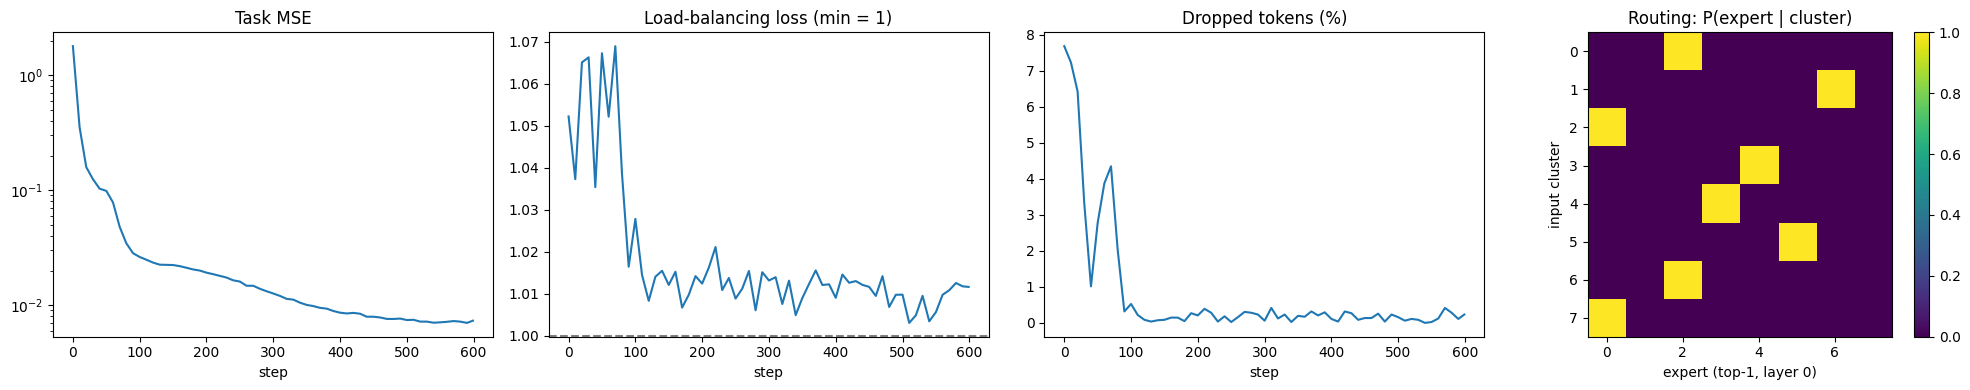

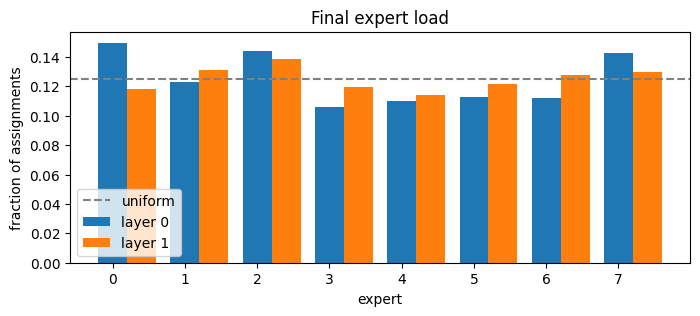

In [13]:
@jax.jit
def top1_expert(params, x):
    # Top-1 expert chosen by the first MoE layer for every token.
    h = rms_norm(x @ params["embed"], params["blocks"][0]["norm"])
    logits = jnp.einsum("gsm,me->gse", h.astype(jnp.float32), params["blocks"][0]["moe"]["router"])
    return jnp.argmax(logits, -1)

x_eval, _, cid_eval = make_batch(jax.random.PRNGKey(999))
choice = np.asarray(top1_expert(params, x_eval)).ravel()
cid = np.asarray(cid_eval).ravel()
conf = np.zeros((N_CLUSTERS, model_cfg.num_experts))
np.add.at(conf, (cid, choice), 1)
conf /= conf.sum(1, keepdims=True)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
s, v = zip(*history["mse"]);       ax[0].plot(s, v); ax[0].set_yscale("log"); ax[0].set_title("Task MSE")
s, v = zip(*history["lb_loss"]);   ax[1].plot(s, v); ax[1].axhline(1.0, ls="--", c="gray"); ax[1].set_title("Load-balancing loss (min = 1)")
s, v = zip(*history["drop_frac"]); ax[2].plot(s, 100 * np.array(v)); ax[2].set_title("Dropped tokens (%)")
im = ax[3].imshow(conf, cmap="viridis", vmin=0, vmax=1)
ax[3].set_xlabel("expert (top-1, layer 0)"); ax[3].set_ylabel("input cluster")
ax[3].set_title("Routing: P(expert | cluster)"); fig.colorbar(im, ax=ax[3])
for a in ax[:3]: a.set_xlabel("step")
plt.tight_layout(); plt.show()

final_load = history["expert_load"][-1][1]
plt.figure(figsize=(8, 3))
for l in range(final_load.shape[0]):
    plt.bar(np.arange(model_cfg.num_experts) + 0.4 * l, final_load[l], width=0.4, label=f"layer {l}")
plt.axhline(1 / model_cfg.num_experts, ls="--", c="gray", label="uniform")
plt.xlabel("expert"); plt.ylabel("fraction of assignments"); plt.title("Final expert load"); plt.legend(); plt.show()

## 9. Benchmark: GSPMD vs `shard_map`

Both versions use the same parameters and batch, timing one full training step (forward + backward + Adam). Numbers on CPU simulation say nothing about TPU speed; run on a real TPU for meaningful timings.

In [14]:
def bench(moe_fn, n_iter=20):
    step = make_train_step(moe_fn)
    p = jax.tree.map(jnp.copy, params)
    o = jax.tree.map(jnp.copy, opt_state)
    x, y, _ = make_batch(jax.random.PRNGKey(7))
    p, o, m = step(p, o, x, y); jax.block_until_ready(m)          # compile + warm-up
    t = time.perf_counter()
    for _ in range(n_iter):
        p, o, m = step(p, o, x, y)
    jax.block_until_ready(m)
    return (time.perf_counter() - t) / n_iter * 1e3

tokens = GLOBAL_GROUPS * GROUP_SIZE
# FLOPs actually computed by experts: 2 matmuls × 2 flops × 3 (fwd+bwd), over E*G*C buffer slots
C = expert_capacity(model_cfg, GROUP_SIZE)
expert_flops = N_LAYERS * 6 * 2 * model_cfg.num_experts * GLOBAL_GROUPS * C * model_cfg.d_model * model_cfg.d_ff

for name, fn in [("GSPMD    ", moe_gspmd), ("shard_map", moe_shard_map)]:
    ms = bench(fn)
    print(f"{name}: {ms:8.2f} ms/step | {tokens / ms * 1e3 / 1e6:6.2f} M tokens/s "
          f"| expert matmuls {expert_flops / ms / 1e9:8.2f} TFLOP/s")

GSPMD    :     2.49 ms/step |   0.82 M tokens/s | expert matmuls    51.66 TFLOP/s
shard_map:     2.51 ms/step |   0.82 M tokens/s | expert matmuls    51.35 TFLOP/s
